# Computational laboratory. Finite difference methods for scalar conservation laws

In physics, a <i>conservation law</i> states that a particular measurable property of an isolated physical system does not change as the system evolves over time. Exact conservation laws include conservation of mass and energy, conservation of linear momentum, conservation of angular momentum, and conservation of electric charge. It is usually expressed mathematically as a partial differential equation which gives a relation between the amount of the quantity and the "transport" of that quantity. It states that the amount of the conserved quantity at a point or within a volume can only change by the amount of the quantity which flows in or out of the volume.

In this notebook, we are interested in the numerical solution of scalar conservation laws in one space dimension, using [finite difference methods](https://en.wikipedia.org/wiki/Finite_difference_method).

The <tt>numpy</tt> and <tt>matplotlib</tt> packages will be needed.

In [1]:
import numpy as np

# To draw matplotlib plots within this notebook.
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

## Exercise 1. A linear problem.
We are interested in solving the following Cauchy problem, comprised of a scalar conservation law
$$
\frac{\partial u}{\partial t}(t,x)+\frac{\partial f(u)}{\partial x}(t,x)=0,\ t>0,\ x\in\mathbb{R},
$$
where $f(u)=c\,u$ (such a choice corresponds to a linear transport equation, the scalar $c$ being the constant advection velocity), and of an initial condition
$$
u(0,x)=u_0(x),\ x\in\mathbb{R},
$$
the function $u_0$ being given.

**Question.** Solve this problem using the [method of characteristics](https://en.wikipedia.org/wiki/Method_of_characteristics) and then implement a function returning the value of the solution $u$ at a given time $t$ and a given point $x$.

Let $x(t)$ satisfy $x'(t)=c$, with $x(0)=\xi$. Then
$$
x(t)=\xi+ct.
$$
Along this characteristic, the chain rule gives
$$
\frac{d}{dt}u(t,x(t))
=u_t+x'(t)u_x
=u_t+cu_x=0.
$$
Thus, $u$ remains constant along the characteristic:
$$
u(t,\xi+ct)=u(0,\xi)=u_0(\xi).
$$
Since $\xi=x-ct$, the solution is
$$
\boxed{u(t,x)=u_0(x-ct)}.
$$
The initial profile is translated without changing shape: to the right if $c>0$ and to the left if $c<0$.

In [8]:
def exact_transport(t, x, u0, c):
    return u0(x - c*t)

In what follows, we assume that the initial datum $u_0$ is a periodic function. In such a situation, the solution $u$ is also a periodic function in the space variable, which allows to restrict the numerical solution of the problem to a bounded subset $[0,T]\times[0,L]$ of $\mathbb{R}_+\times\mathbb{R}$, where the real number $L$ is a period of the function $u_0$, by adding to the preceding equations the following periodicity condition
$$
u(t,0)=u(t,L),\ t\in[0,T].
$$

In the present case, we set $T=3$, $L=4$ and $c=1$, the restriction of the initial datum to $[0,L]$ being
$$
u_0(x)=\begin{cases}1&\text{if }1\leq x\leq 2,\\0&\text{else.}\end{cases}
$$

In [9]:
T, L, c = 3., 4., 1

def u0(x): 
    return ((x%L >= 1.) & (x%L <= 2.)).astype(float)

In order to compute a numerical approximation to the solution of the problem by the finite difference method, we first define a uniform Cartesian discretisation grid of the domain $[0,T]\times[0,L]$ and the quotient $\lambda=\frac{\Delta t}{\Delta x}$, $\Delta t$ and $\Delta x$ being the lengths of the time and space steps, respectively.

The numerical approximation of the solution to the problem will then be obtained by using successively:

- the forward in time centered in space scheme ([FTCS](http://en.wikipedia.org/wiki/FTCS_scheme)),
$$
u^{n+1}_j=u^n_j-c\lambda\,\frac{u^n_{j+1}-u^n_{j-1}}{2},\ n\in\mathbb{N},\ j\in\mathbb{Z},
$$
- the scheme of the [Lax-Friedrichs method](http://en.wikipedia.org/wiki/Lax%E2%80%93Friedrichs_method),
$$
u^{n+1}_j=\frac{(1-c\lambda)\,u^n_{j+1}+(1+c\lambda)\,u^n_{j-1}}{2},\ n\in\mathbb{N},\ j\in\mathbb{Z},
$$
- the scheme of the [Lax-Wendroff method](http://en.wikipedia.org/wiki/Lax%E2%80%93Wendroff_method),
$$
u^{n+1}_j=u^n_j-c\lambda\,\frac{u^n_{j+1}-u^n_{j-1}}{2}+(c\lambda)^2\,\frac{u^n_{j+1}-2\,u^n_j+u^n_{j-1}}{2},\ n\in\mathbb{N},\ j\in\mathbb{Z}.
$$

We recall that each of the three-point schemes given above can be written in *conservative form*, that is
$$
u^{n+1}_j=u^n_j-\lambda\left(h(u^n_j,u^n_{j+1})-h(u^n_{j-1},u^n_j)\right),\ n\in\mathbb{N},\ j\in\mathbb{Z},
$$
where the function $h$ is the numerical flux associated with the scheme, satisfying the *consistency condition* $h(u,u)=f(u)$.

**Question.** Determine the numerical fluxes associated with the conservative form of the above schemes and implement their corresponding functions.

Write the conservative update as
$$
u_j^{n+1}
=u_j^n-\lambda\left(h(u_j^n,u_{j+1}^n)-h(u_{j-1}^n,u_j^n)\right).
$$
Consider a numerical flux of the form
$$
h(a,b)=\frac{c}{2}(a+b)-\frac{d}{2}(b-a).
$$
Substitution gives
$$
u_j^{n+1}
=u_j^n-\frac{c\lambda}{2}(u_{j+1}^n-u_{j-1}^n)
+\frac{d\lambda}{2}(u_{j+1}^n-2u_j^n+u_{j-1}^n).
$$

Matching coefficients with each scheme yields:

- **FTCS:** $d=0$, hence
  $$
  \boxed{h_{\mathrm{FTCS}}(a,b)=\frac{c}{2}(a+b)}.
  $$

- **Lax-Friedrichs:** $d=1/\lambda$, hence
  $$
  \boxed{h_{\mathrm{LF}}(a,b)=\frac{c}{2}(a+b)-\frac{b-a}{2\lambda}}.
  $$

- **Lax-Wendroff:** $d=c^2\lambda$, hence
  $$
  \boxed{h_{\mathrm{LW}}(a,b)=\frac{c}{2}(a+b)-\frac{c^2\lambda}{2}(b-a)}.
  $$

All three satisfy the consistency condition $h(u,u)=cu=f(u)$.

In [11]:
def flux_ftcs(a, b, c, lam):
    return c * (a + b) / 2.

def flux_lf(a, b, c, lam):
    return c * (a + b) / 2. - (b - a) / (2. * lam)

def flux_lw(a, b, c, lam):
    return c * (a + b) / 2 - c**2 * lam * (b - a) / 2.

**Question.** Compute a numerical approximation to the solution of the problem with each of the three schemes, using $500$ steps in space and choosing the mesh ratio so that $|c|\lambda=0.9$.

In [28]:
def solve_linear_transport(L, T, c, N=500, scheme="FTCS"):
    dx = L / N
    lam = 0.9 / np.abs(c)
    dt = lam * dx
    
    # choose flux
    flux_dict = {"FTCS": flux_ftcs, "LF": flux_lf, "LW": flux_lw}

    if scheme not in flux_dict:
        raise ValueError("scheme must be 'FTCS', 'LF', or 'LW'")

    flux = flux_dict[scheme]

    Nts = int(np.ceil(T / dt))

    # Adjust the time step to end exactly at T.
    dt = T / Nts
    lam = dt / dx

    # create spacetime grid
    x = np.linspace(0, L, N, endpoint=False)
    t = np.linspace(0, T, Nts + 1)

    u = np.zeros((Nts + 1, N))
    # initial condition
    u[0, :] = u0(x)

    # scheme iteration
    for i in range(Nts):
        current = u[i, :]
        u_right = np.roll(current, -1)
        u_left = np.roll(current, 1)

        u[i+1, :] = current - lam * (
            flux(current, u_right, c, lam)
            - flux(u_left, current, c, lam)
        )

    return x, t, u

**Question.** Using the code given below, make animations plotting the computed numerical approximation together with the exact solution of the problem. Comment.

In [33]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from matplotlib.animation import PillowWriter

schemes = ["FTCS", "LF", "LW"]

results = {
    scheme: solve_linear_transport(L, T, c, N=500, scheme=scheme)
    for scheme in schemes
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
exact_lines = []
numerical_lines = []

for ax, scheme in zip(axes, schemes):
    ax.set_xlim(0, L)
    ax.set_ylim(-0.5, 1.5)
    ax.set_title(scheme)
    ax.set_xlabel("$x$")

    exact_line, = ax.plot([], [], "k--", lw=2, label="Exact")
    numerical_line, = ax.plot([], [], lw=1.5, label="Numerical")

    exact_lines.append(exact_line)
    numerical_lines.append(numerical_line)
    ax.legend()

axes[0].set_ylabel("$u(t,x)$")
time_label = fig.suptitle(
    "Periodic linear transport: FTCS, Lax-Friedrichs and Lax-Wendroff"
)

# All schemes use the same grid.
x, t, _ = results["FTCS"]

# Include the final time while limiting animation size.
frames = np.unique(
    np.linspace(0, len(t)-1, min(150, len(t)), dtype=int)
)

def animate(i):
    for p, scheme in enumerate(schemes):
        x, t, U = results[scheme]

        x_plot = np.append(x, L)
        numerical = np.append(U[i, :], U[i, 0])

        exact_lines[p].set_data(x_plot, u0(x_plot - c*t[i]))
        numerical_lines[p].set_data(x_plot, numerical)

    time_label.set_text(
        "Periodic linear transport: numerical schemes vs exact solution\n"
        f"t = {t[i]:.3f}, c = {c:g}, N = {len(x)}, "
        f"CFL = {abs(c)*(t[1]-t[0])/(x[1]-x[0]):.3f}"
    )
    return (*exact_lines, *numerical_lines, time_label)

fig.tight_layout(rect=[0, 0, 1, 0.85])

time_label.set_y(0.98)
time_label.set_fontsize(12)
fig.subplots_adjust(top=0.75, bottom=0.15, wspace=0.25)

animation = FuncAnimation(
    fig,
    animate,
    frames=frames,
    interval=60,
    blit=False
)

animation.save(
    "linear_transport_comparison.gif",
    writer=PillowWriter(fps=24),
    dpi=200
)

plt.close(fig)
HTML(animation.to_jshtml())

The exact solution translates the initial rectangular profile at velocity $c$, wrapping around the periodic domain.

- **FTCS:** growing oscillations develop, demonstrating instability even though $|c|\Delta t/\Delta x\leq0.9$.
- **Lax-Friedrichs:** the solution remains stable, but numerical diffusion smooths the sharp edges.
- **Lax-Wendroff:** the profile remains sharper, but oscillations appear near the discontinuities.

The CFL condition ensures stability for LF and LW here, but does not stabilise FTCS.


## Exercise 2. A non-linear problem.
We are interested in solving the Cauchy problem defined in the preceding exercise, but with a flux now equal to $f(u)=\frac{u^2}{2}$ (this choice corresponds to the inviscid [Burgers equation](https://en.wikipedia.org/wiki/Burgers%27_equation)) and the initial datum
$$
u_0(x)=\begin{cases}1&\text{if }0\leq x\leq 1,\\0&\text{else.}\end{cases}
$$
To compute an approximation to this conservation law, we replace the real line $\mathbb{R}$ by the bounded computational interval $[-1,4]$ and impose the homogeneous boundary conditions
$$
u(t,-1)=u(t,4)=0.
$$
These conditions should be understood as artificial far-field boundary conditions for the original Cauchy problem. Their use is justified by the compact support of the initial datum and by the finite propagation speed of the equation. For Burgers' equation, the characteristic speed is $f'(u)=u$.

The final time considered for the computation is $T=3$.

In [34]:
T = 3.
def u0(x):
    return ((x >= 0.) & (x <= 1.)).astype(float)

**Question.** Determine the unique entropy solution of the problem and implement a function returning the value of this solution at a given time $t$ and a given point $x$.

**Answer.** With such an initial datum, one must distinguish three zones for the characteristic curves since
$$
x(t)=\begin{cases}x_0&\text{if }x_0\leq0,\\t+x_0&\text{if }0<x_0\leq1,\\x_0&\text{if }x_0>1,\end{cases}\ x_0\in\mathbb{R}.
$$
The curves of the second and third region intersect at the initial time $t=0$. The flux in the equation being a strictly convex function, the Lax entropy condition states that a shock is admissible if the value of the solution to its left is strictly larger than the value to its right. The second discontinuity in the initial datum hence produces a shock wave emanating from $x=1$ and travelling along a curve, parametrised by the function $t\mapsto\xi(t)$, at a speed given by the [Rankine-Hugoniot condition](https://en.wikipedia.org/wiki/Rankine%E2%80%93Hugoniot_conditions):
$$
\xi'(t)=\frac{f(1)-f(0)}{1-0}=\frac{1}{2},
$$
so that $\xi(t)=\frac{1}{2}\,t+1$. On the other hand, the first discontinuity in the initial datum gives birth to a rarefaction wave, associated to curves $\frac{x}{t}=\text{constant}$ filling the area between the first and second zones without characteristic curves to define the solution. The unique entropy solution to the problem is thus given by
$$
u(t,x)=\begin{cases}0&\text{if }x<0,\\\dfrac{x}{t}&\text{if }0<x<t,\\1&\text{if }t<x<1+\dfrac{t}{2},\\0&\text{if }x>1+\dfrac{t}{2},\end{cases}\text{ for }0<t<t^*,
$$
up to a time $t^*$ satisfying $t^*=1+\frac{t^*}{2}$, that is $t^*=2$, for which the rarefaction wave meets the shock wave. For $t>2$, a discontinuity separates the rarefaction wave on the left from the vacuum (that is, the constant state with value $0$) on the right. Using once again the Rankine-Hugoniot conditions, we find that the function $\xi$ parametrising the discontinuity curve satisfies
$$
\xi'(t)=\frac{f(0)-f\left(\frac{\xi(t)}{t}\right)}{0-\frac{\xi(t)}{t}}=\frac{1}{2t}\,\xi(t),\ \xi(2)=2,
$$
so that $\xi(t)=\sqrt{2t}$ and finally
$$
u(t,x)=\begin{cases}0&\text{if }x<0,\\\dfrac{x}{t}&\text{if }0<x<\sqrt{2t},\\0&\text{if }x>\sqrt{2t},\end{cases}\text{ for }t>2.
$$

We observe that, for $0<t<2$, the entropy solution is supported in $\left[0,1+\frac{t}{2}\right]$. For $t\geq2$, the solution is supported in $[0,\sqrt{2t}]$. Consequently, up to the final time $T=3$, its support is contained in $[0,\sqrt{6}]$, with $\sqrt{6}\simeq2.45<4$. The solution is therefore identically zero in neighbourhoods of both $x=-1$ and $x=4$ for every $t$ in $[0,3]$.

The chosen computational interval is thus sufficiently large that the propagating solution does not interact with its endpoints during the simulation.

In [35]:
def solution(t, x):
    x = np.asarray(x)
    if t == 0:
        return u0(x).astype(float)
    if t < 2:
        return np.where((x >= 0) & (x < t), x/t, np.where((x >= t) & (x < 1.0 + 0.5 * t), 1., 0.))
    return np.where((x >= 0) & (x < np.sqrt(2.*t)), x/t, 0.)

Since the flux $f$ is non-linear, we use the following adaptations for the schemes of the Lax-Friedrichs method 
$$
u_j^{n+1}=\frac{1}{2}\,\left(u_{j+1}^n+u_{j-1}^n\right)-\frac{\lambda}{2}\,\left(f(u_{j+1}^n)-f(u_{j-1}^n)\right),\ n\in\mathbb{N},\ j\in\mathbb{Z},
$$
and of the Lax-Wendroff method
$$
u_j^{n+1}=u_j^n-\frac{\lambda}{2}\,\left(f(u_{j+1}^n)-f(u_{j-1}^n)\right)+\frac{\lambda^2}{2}\left(f'\left(\frac{u_{j+1}^n+u_j^n}{2}\right)\left(f(u_{j+1}^n)-f(u_j^n)\right)-f'\left(\frac{u_j^n+u_{j-1}^n}{2}\right)\left(f(u_j^n)-f(u_{j-1}^n)\right)\right),\ n\in\mathbb{N},\ j\in\mathbb{Z},
$$
to numerically solve the problem.

**Question.** Use these two methods to numerically approximate the entropy solution of the problem. The Courant number will be fixed to the value $0.9$ in the CFL condition $\lambda\max_j\left|f'(u_j^n)\right|\leq 1$.

In [43]:
def f(u):
    return u**2 / 2


def step_ftcs(u, lam):
    left, centre, right = u[:-2], u[1:-1], u[2:]
    
    new = np.zeros_like(u)
    new[1:-1] = centre - lam/2. * (f(right) - f(left))
    
    return new


def step_lf(u, lam):
    left, centre, right = u[:-2], u[1:-1], u[2:]
    
    new = np.zeros_like(u)
    new[1:-1] = (
        (right + left) / 2.
        - lam / 2. * (f(right) - f(left))
    )
    
    return new


def step_lw(u, lam):
    left, centre, right = u[:-2], u[1:-1], u[2:]
    f_left, f_centre, f_right = f(left), f(centre), f(right)

    # f'(v) = v for Burgers' equation.
    speed_right = (right + centre)/2
    speed_left = (centre + left)/2

    new = np.zeros_like(u)
    new[1:-1] = (
        centre
        - lam/2 * (f_right - f_left)
        + lam**2/2 * (
            speed_right * (f_right - f_centre)
            - speed_left * (f_centre - f_left)
        )
    )
    return new

In [44]:
def solve_burgers(u0, T=3., a=-1., b=4., N=500,
                  scheme="LF", nu=0.9):
    steps = {
        "FTCS": step_ftcs,
        "LF": step_lf,
        "LW": step_lw,
    }

    if scheme not in steps:
        raise ValueError("scheme must be 'FTCS', 'LF', or 'LW'")
    if not 0 < nu <= 1:
        raise ValueError("nu must satisfy 0 < nu <= 1")

    step = steps[scheme]

    # N spatial intervals, including both endpoints.
    x = np.linspace(a, b, N + 1)
    dx = (b - a) / N

    current = np.asarray(u0(x), dtype=float).copy()
    current[0] = current[-1] = 0.

    times = [0.]
    history = [current.copy()]

    while times[-1] < T:
        remaining = T - times[-1]
        max_speed = np.max(np.abs(current))

        dt = (
            min(nu * dx / max_speed, remaining)
            if max_speed > 0 else remaining
        )

        if times[-1] + dt == times[-1]:
            raise RuntimeError("Time step became too small; check instability.")

        current = step(current, dt / dx)

        if not np.all(np.isfinite(current)):
            raise RuntimeError("Non-finite solution; the scheme became unstable.")

        times.append(T if dt == remaining else times[-1] + dt)
        history.append(current.copy())

    return x, np.array(times), np.stack(history)

In [45]:
T = 3.

def u0(x):
    return ((x >= 0.) & (x <= 1.)).astype(float)

x_lf, t_lf, U_lf = solve_burgers(u0, T=T, scheme="LF")
x_lw, t_lw, U_lw = solve_burgers(u0, T=T, scheme="LW")

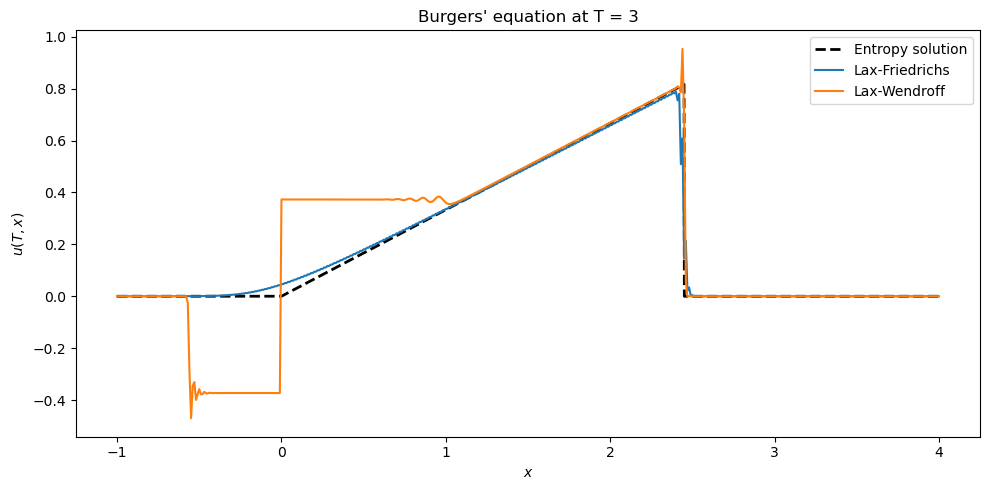

In [47]:
x_fine = np.linspace(-1, 4, 3000)

plt.figure(figsize=(10, 5))
plt.plot(x_fine, solution(T, x_fine), "k--", lw=2, label="Entropy solution")
plt.plot(x_lf, U_lf[-1], label="Lax-Friedrichs")
plt.plot(x_lw, U_lw[-1], label="Lax-Wendroff")
plt.xlabel("$x$")
plt.ylabel("$u(T,x)$")
plt.title(f"Burgers' equation at T = {T:g}")
plt.legend()
plt.tight_layout()
plt.show()

**Question.** Make animations using the code given in the preceding exercise (the size of the animation window will be modified as indicated below). What can be said of the computed numerical approximations?

In [50]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

T = 3.
N = 500
nu = 0.9
schemes = ["LF", "LW"]
names = {"LF": "Lax-Friedrichs", "LW": "Lax-Wendroff"}

results = {
    scheme: solve_burgers(u0, T=T, N=N, scheme=scheme, nu=nu)
    for scheme in schemes
}

frame_times = np.linspace(0., T, 150)
x_exact = np.linspace(-1., 4., 3000)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
exact_lines = []
numerical_lines = []

for ax, scheme in zip(axes, schemes):
    ax.set_xlim(-1., 4.)
    ax.set_ylim(-0.5, 1.5)
    ax.set_title(names[scheme])
    ax.set_xlabel("$x$")

    exact_line, = ax.plot([], [], "k--", lw=2,
                          label="Entropy solution")
    numerical_line, = ax.plot([], [], lw=1.5,
                              label="Numerical")

    exact_lines.append(exact_line)
    numerical_lines.append(numerical_line)
    ax.legend()

axes[0].set_ylabel("$u(t,x)$")
title = fig.suptitle("", fontsize=12)
fig.subplots_adjust(top=0.76, bottom=0.15, wspace=0.15)


def interpolate_time(tau, times, U):
    """Interpolate between stored time levels for display."""
    k = np.searchsorted(times, tau, side="right") - 1
    k = np.clip(k, 0, len(times) - 2)

    weight = (tau - times[k]) / (times[k+1] - times[k])
    return (1 - weight)*U[k] + weight*U[k+1]


def animate(tau):
    for p, scheme in enumerate(schemes):
        x, times, U = results[scheme]
        numerical = interpolate_time(tau, times, U)

        exact_lines[p].set_data(x_exact, solution(tau, x_exact))
        numerical_lines[p].set_data(x, numerical)

    title.set_text(
        "Burgers' equation: numerical approximations vs entropy solution\n"
        f"t = {tau:.3f}, N = {N}, target CFL = {nu}"
    )

    return (*exact_lines, *numerical_lines, title)


animation = FuncAnimation(
    fig,
    animate,
    frames=frame_times,
    interval=1000/24,
    blit=False
)

animation.save(
    "burgers_comparison.gif",
    writer=PillowWriter(fps=24),
    dpi=200
)

plt.close(fig)
HTML(animation.to_jshtml())

Both approximations capture the rarefaction wave emerging from $x=0$ and the shock emerging from $x=1$. These waves meet at $t=2$, after which the shock follows $x=\sqrt{2t}$ and its height decreases.

- **Lax-Friedrichs** produces a diffusive approximation: the shock is smeared over several grid points.
- **Lax-Wendroff** gives a sharper shock but introduces nonphysical oscillations near it, including possible overshoots and undershoots.

The exact solution remains between $0$ and $1$. Oscillations outside this range are numerical artifacts, not features of the entropy solution.